importing the libraries

In [149]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

load and take glance of dataset

In [150]:
df = pd.read_csv('/content/Student Social Media And Mental Health Impact.csv')

In [151]:
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


removing duplicate rows

In [152]:
df = df.drop_duplicates()

In [153]:
df.shape

(4998, 13)

In [154]:
df.isnull().sum()

,0
Age,0
Gender,0
Country,0
Academic_Level,0
Most_Used_Platform,0
Purpose_Of_Use,0
Avg_Daily_Usage_Hours,0
Daily_Unlocks,0
Study_Hours,0
Physical_Activity_Hours,0


which to encode

In [155]:
df.info()
# we will incode whose data type is object

<class 'pandas.core.frame.DataFrame'>
Index: 4998 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      4998 non-null   int64  
 1   Gender                   4998 non-null   object 
 2   Country                  4998 non-null   object 
 3   Academic_Level           4998 non-null   object 
 4   Most_Used_Platform       4998 non-null   object 
 5   Purpose_Of_Use           4998 non-null   object 
 6   Avg_Daily_Usage_Hours    4998 non-null   float64
 7   Daily_Unlocks            4998 non-null   int64  
 8   Study_Hours              4998 non-null   float64
 9   Physical_Activity_Hours  4998 non-null   float64
 10  Sleep_Hours_Per_Night    4998 non-null   float64
 11  Stress_Level             4998 non-null   object 
 12  Mental_Health_Score      4998 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 546.7+ KB


In [156]:
df.describe()
# slightly issue in physical activity hours (cant be negative)

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000
mean,20.822129,5.078491,171.455582,3.008403,1.750760,6.634654,6.231152
std,1.736774,1.654097,42.859829,1.636831,0.668406,1.221561,1.278476
min,18.000000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


EDA

we will check the distribution of the target variable

<Axes: xlabel='Mental_Health_Score', ylabel='Count'>

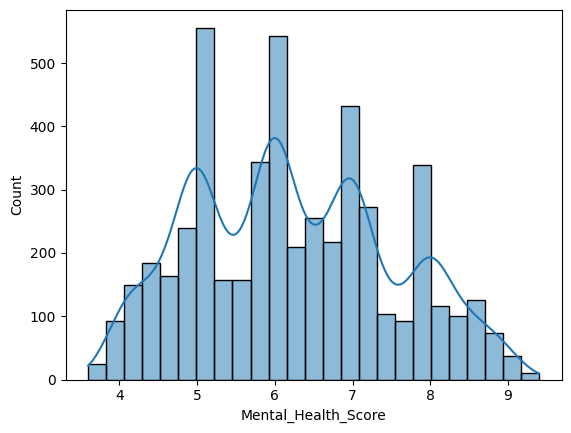

In [157]:
sns.histplot(df['Mental_Health_Score'] , kde=True)

correlation heatmap (which numeric features move with the target)

<Axes: >

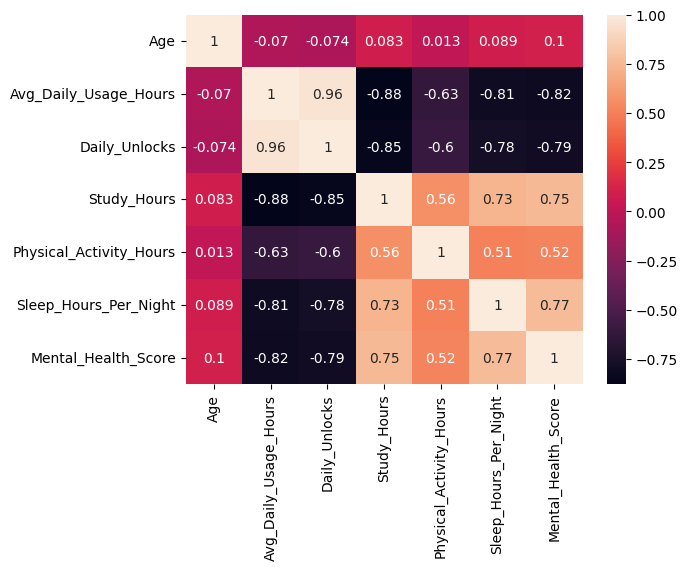

In [158]:
from __future__ import annotations
sns.heatmap(df.corr(numeric_only=True) , annot=True)

stress level vs mental health score

In [159]:
df['Stress_Level'].value_counts()

,count
Stress_Level,
Very High,1621
High,1439
Medium,1295
Low,643


In [160]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

In [161]:
df['Stress_Level']

,Stress_Level
0,Medium
1,Low
2,Medium
3,Very High
4,Very High
...,...
4995,Low
4996,Very High
4997,Medium
4998,Medium


In [162]:
df['Stress_Level'].unique()

array(['Medium', 'Low', 'Very High', 'High'], dtype=object)

<Axes: xlabel='Stress_Level', ylabel='Mental_Health_Score'>

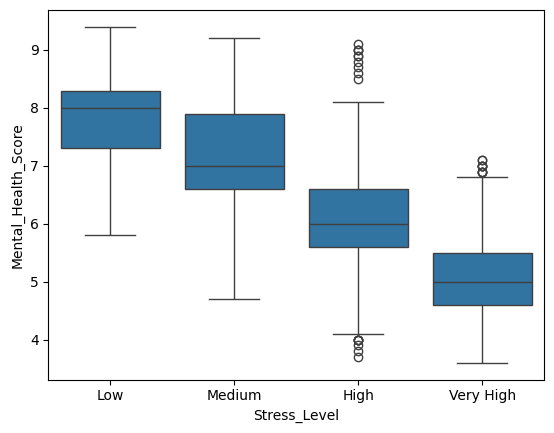

In [163]:
order = ['Low' , 'Medium' , 'High' ,  'Very High' ]
sns.boxplot(x='Stress_Level' , y='Mental_Health_Score' , data=df , order=order)

daily usage hours vs mental health score

<Axes: xlabel='Avg_Daily_Usage_Hours', ylabel='Mental_Health_Score'>

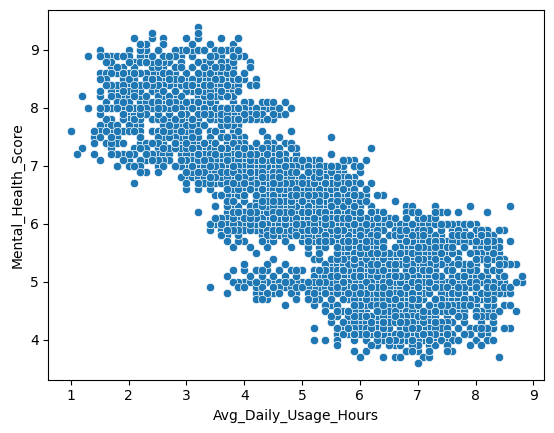

In [164]:
sns.scatterplot(data=df , x='Avg_Daily_Usage_Hours' , y='Mental_Health_Score' )

sleep hours vs mental health score

<Axes: xlabel='Sleep_Hours_Per_Night', ylabel='Mental_Health_Score'>

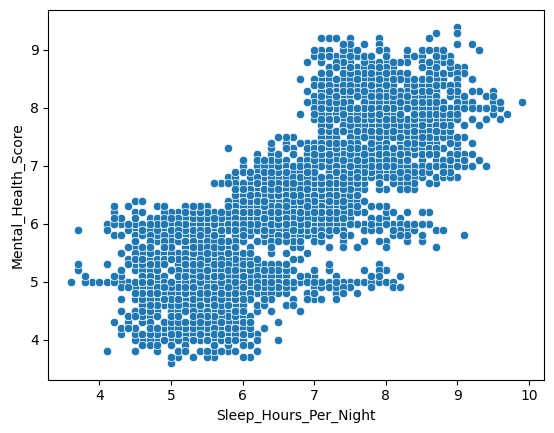

In [165]:
sns.scatterplot(data=df , x='Sleep_Hours_Per_Night' , y='Mental_Health_Score' )

In [166]:
# there is a positive correlation


daily unlocks vs mental health score

<Axes: xlabel='Daily_Unlocks', ylabel='Mental_Health_Score'>

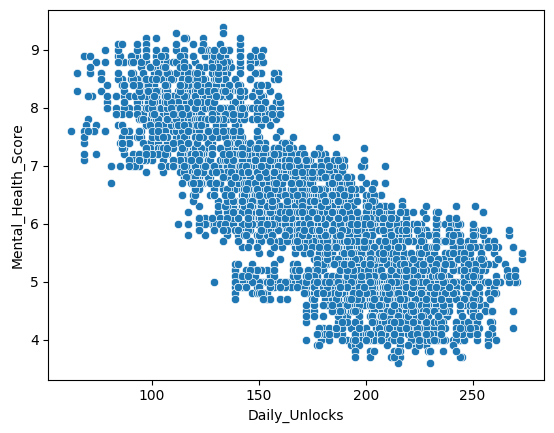

In [167]:
sns.scatterplot(data=df , x='Daily_Unlocks' , y='Mental_Health_Score'  )

In [168]:
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


study hours vs mental health score

<Axes: xlabel='Study_Hours', ylabel='Mental_Health_Score'>

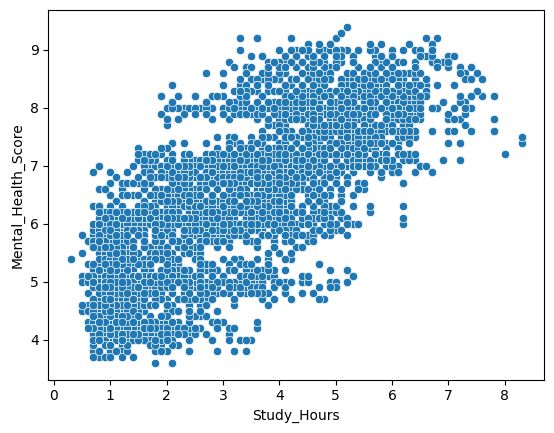

In [169]:
sns.scatterplot(data=df , x='Study_Hours' , y='Mental_Health_Score')

physical activity hours vs mental health score

<Axes: xlabel='Physical_Activity_Hours', ylabel='Mental_Health_Score'>

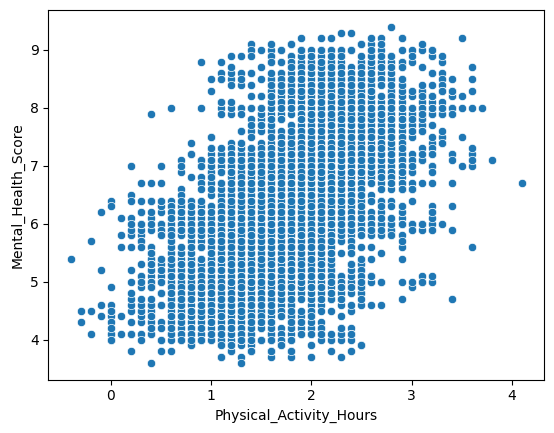

In [170]:
sns.scatterplot(data=df , x='Physical_Activity_Hours' , y='Mental_Health_Score' )

age vs mental health score

<Axes: xlabel='Age', ylabel='Mental_Health_Score'>

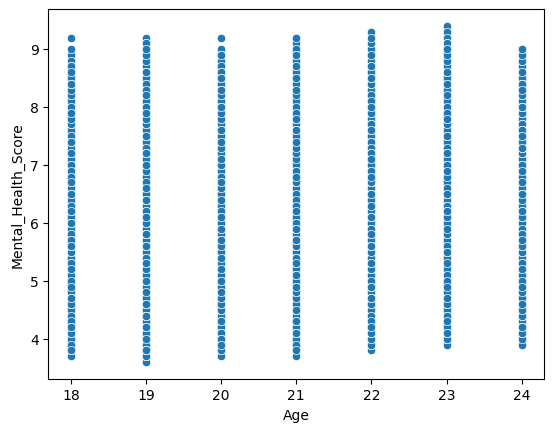

In [171]:
sns.scatterplot(data=df , x='Age' , y='Mental_Health_Score')

most used platform

In [172]:
platforms = df['Most_Used_Platform'].value_counts()

<Axes: xlabel='Most_Used_Platform', ylabel='count'>

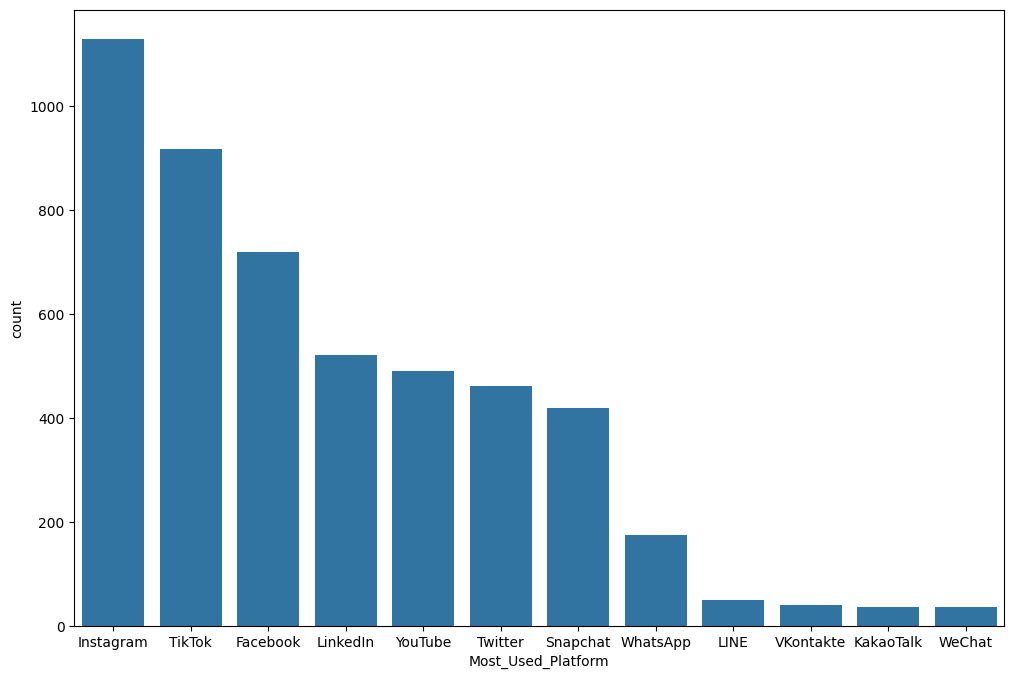

In [173]:
plt.figure(figsize=(12,8))
sns.countplot(x='Most_Used_Platform' , data=df , order=platforms.index)

Checking Outliers

In [174]:
numeric_features = df.select_dtypes(include='number')
quartile1 = numeric_features.quantile(0.25)
quartile3 = numeric_features.quantile(0.75)

IQR = quartile3 - quartile1

lowerBound = quartile1 - 1.5 * IQR
upperBound = quartile3 + 1.5 * IQR

In [175]:
outliers = (numeric_features < lowerBound) | (numeric_features > upperBound)
outliers.sum()

,0
Age,0
Avg_Daily_Usage_Hours,0
Daily_Unlocks,0
Study_Hours,2
Physical_Activity_Hours,22
Sleep_Hours_Per_Night,0
Mental_Health_Score,0


Data Cleaning

In [176]:
# drop duplicates
df = df.drop_duplicates()

In [177]:
# in physical hours min is negative which cant be possible
df['Physical_Activity_Hours'] = df['Physical_Activity_Hours'].clip(lower=0)

In [178]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000
mean,20.822129,5.078491,171.455582,3.008403,1.751160,6.634654,6.231152
std,1.736774,1.654097,42.859829,1.636831,0.667282,1.221561,1.278476
min,18.000000,1.000000,62.000000,0.300000,0.000000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


 Checking Skweness

In [179]:
# only for numeric cols

In [180]:
numeric_features = df.select_dtypes(include='number')
numeric_features.skew()

,0
Age,0.155008
Avg_Daily_Usage_Hours,0.005575
Daily_Unlocks,0.002309
Study_Hours,0.436125
Physical_Activity_Hours,0.053288
Sleep_Hours_Per_Night,0.123919
Mental_Health_Score,0.207086


In [181]:
#  if skew is near to zero it is centrally inclined (0.03 , -0.12 etc )
#  if skew is negative then left skewed -1.23
#  if skewed is positive then right skewed 1.23

# from skewness we can say how our data is spread , like linear regression wont work in there is no skewness , but tree based models dont depend on skew .


In [182]:
# we can treat skewness via log transformation and power transformation .

Feature Engineering

In [183]:
# since countries column has 100 of values we cant just apply one hot encoding , it will be very high inefficient
# we will take top most frequent countries and other refer as others

In [184]:
unique_countries = df['Country'].value_counts().index[:10].to_list()

In [185]:
def group_countries(country) :
  if country in unique_countries :
    return country
  return 'Other'

In [186]:
df['grouped_Country'] = df['Country'].apply(group_countries)

In [187]:

df['Country'].value_counts()


,count
Country,
Other,1879
India,389
USA,354
Canada,230
Australia,198
...,...
Armenia,1
Bosnia,1
Kuwait,1


In [188]:
df.head()
df['Country'].value_counts()
df['grouped_Country'].value_counts()

,count
grouped_Country,
Other,3231
India,389
USA,354
Canada,230
Australia,198
UK,185
Germany,136
Mexico,94
Turkey,94


Encoding Strategies

In [189]:
# stress level can be 0 1 2 3 because there is a natural order
# otherwise do one hot encoding

Train Test Split

In [190]:
# first we will split the data into training and testing
# do preprocessing in training data not on testing
# also called as data leakage

In [191]:
# every column requirements
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score,grouped_Country
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8,Other
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6,Other
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0,Canada
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3,Other
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4,Other


In [192]:
# Apply log transformation here
skews_col = ['Study_Hours']

# apply standardization
other_numeric_cols = ['Age' , 'Avg_Daily_Usage_Hours' , 'Daily_Unlocks' , 'Physical_Activity_Hours' , 'Sleep_Hours_Per_Night']

# apply ordinal encoding
ordinal_col = ['Stress_Level']

# normal col one hot encoding
normal_col = ['Gender' , 'grouped_Country' ,'Academic_Level' ,  'Most_Used_Platform' , 'Purpose_Of_Use'   ]

In [193]:
feature_col = skews_col + other_numeric_cols + ordinal_col + normal_col

In [194]:
X = df[feature_col]
y = df['Mental_Health_Score']

In [195]:
from sklearn.model_selection import train_test_split

X_train , X_test , y_train , y_test = train_test_split(X  , y , random_state=42 , test_size=0.3)

In [196]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing  import FunctionTransformer , StandardScaler , OrdinalEncoder , OneHotEncoder
from sklearn.compose import ColumnTransformer

skew_pipeline = Pipeline(steps=[
    ('log_transform' , FunctionTransformer(np.log1p)) ,
    ('scale' , StandardScaler())
])


plain_numeric_pipeline = Pipeline(steps =[
    ('scale' , StandardScaler())
])


ordinal_pipeline  = Pipeline( steps = [
    ('encode'  , OrdinalEncoder(categories = [['Low' , 'Medium' , 'High' , 'Very High' ]]))
]
)

nominal_pipeline = Pipeline(steps = [
    ('encode' ,  OneHotEncoder(handle_unknown='ignore'))
])


#  column tranformer will work as the gate for the pipelines

# (which pipeline , feature)

preprocessor = ColumnTransformer(
    transformers=[
        ('skew_pipeline' , skew_pipeline , skews_col) ,
        ('plain_numeric_pipeline' , plain_numeric_pipeline , other_numeric_cols ) ,
        ('ordinal_pipeline' , ordinal_pipeline  , ordinal_col ) ,
        ('norminal_pipeline' , nominal_pipeline , normal_col )
    ]
)

Base Line Model (Linear Regression)

In [197]:
from sklearn.linear_model import LinearRegression

lr_pipeline = Pipeline(steps=[
    ('preprocessor' , preprocessor) ,
    ('regressor' , LinearRegression())
])

lr_pipeline.fit(X_train , y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('skew_pipeline',
                                                  Pipeline(steps=[('log_transform',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['Study_Hours']),
                                                 ('plain_numeric_pipeline',
                                                  Pipeline(steps=[('scale',
                                                                   StandardScaler())]),
                                                  ['Age',
                                                   'Avg_Daily_Usage_Hours',
                                                   'Daily_Unlocks',
                                                   'Physical_Activity_Hours',
                                                   'Sle...ht']),
                                                 ('ordinal_pipeline',
                                                  Pipeline(steps=[('encode',
                                                                   OrdinalEncoder(categories=[['Low',
                                                                                               'Medium',
                                                                                               'High',
                                                                                               'Very '
                                                                                               'High']]))]),
                                                  ['Stress_Level']),
                                                 ('norminal_pipeline',
                                                  Pipeline(steps=[('encode',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Gender', 'grouped_Country',
                                                   'Academic_Level',
                                                   'Most_Used_Platform',
                                                   'Purpose_Of_Use'])])),
                ('regressor', LinearRegression())])

In [198]:
y_pred_testing = lr_pipeline.predict(X_test)
y_pred_training = lr_pipeline.predict(X_train)

In [199]:
from sklearn.metrics import  r2_score , mean_absolute_error , mean_squared_error

r2_testing = r2_score(y_test , y_pred_testing)
r2_training = r2_score(y_train , y_pred_training)


mean_abs_testing = mean_absolute_error(y_test , y_pred_testing)
mean_abs_training = mean_absolute_error(y_train , y_pred_training)

mean_squared_testing = mean_squared_error(y_test , y_pred_testing)
mean_squared_training = mean_squared_error(y_train , y_pred_training)


In [200]:
r2_testing , r2_training

(0.739794461743302, 0.7236771199387539)

In [201]:
# there is no chance of overfitting

In [202]:
mean_abs_testing , mean_abs_training

(0.5361775634720183, 0.5189846926901907)

In [203]:
mean_squared_testing , mean_squared_training

(0.45701905273488, 0.4367848338582864)

Random Forest Regression

In [204]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline(steps=[
    ('preprocessor' , preprocessor) ,
    ('regressor' , RandomForestRegressor(random_state=42))
])

rf_pipeline.fit(X_train , y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('skew_pipeline',
                                                  Pipeline(steps=[('log_transform',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['Study_Hours']),
                                                 ('plain_numeric_pipeline',
                                                  Pipeline(steps=[('scale',
                                                                   StandardScaler())]),
                                                  ['Age',
                                                   'Avg_Daily_Usage_Hours',
                                                   'Daily_Unlocks',
                                                   'Physical_Activity_Hours',
                                                   'Sle...
                                                 ('ordinal_pipeline',
                                                  Pipeline(steps=[('encode',
                                                                   OrdinalEncoder(categories=[['Low',
                                                                                               'Medium',
                                                                                               'High',
                                                                                               'Very '
                                                                                               'High']]))]),
                                                  ['Stress_Level']),
                                                 ('norminal_pipeline',
                                                  Pipeline(steps=[('encode',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Gender', 'grouped_Country',
                                                   'Academic_Level',
                                                   'Most_Used_Platform',
                                                   'Purpose_Of_Use'])])),
                ('regressor', RandomForestRegressor(random_state=42))])

In [205]:
rf_y_pred_testing = rf_pipeline.predict(X_test)
rf_y_pred_training = rf_pipeline.predict(X_train)

In [206]:
from sklearn.metrics import  r2_score , mean_absolute_error , mean_squared_error

rf_r2_testing = r2_score(y_test , rf_y_pred_testing)
rf_r2_training = r2_score(y_train , rf_y_pred_training)


rf_mean_abs_testing = mean_absolute_error(y_test , rf_y_pred_testing)
# rf_mean_abs_training = mean_absolute_error(y_train , rf_y_pred_training)

# rf_mean_squared_testing = mean_squared_error(y_test , rf_y_pred_testing)
# rf_mean_squared_training = mean_squared_error(y_train , rf_y_pred_training)

Hyper Parameter tuning with random search CV

In [207]:
rf_r2_testing , rf_r2_training

(0.8772109489481038, 0.980826112682599)

In [208]:
# testing accuracy matters the most rather than training accuracy

Randomized Search CV using
 Hyperparameter Tuning




In [213]:
param_grid = {
    'regressor__n_estimators' : [100 , 200 , 300] ,
    'regressor__max_depth' : [5 , 10 , 15 ] ,
    'regressor__min_samples_split' : [2 , 5 , 10] ,
    'regressor__min_samples_leaf' : [1 , 2 , 4]
}

In [214]:
from sklearn.model_selection import  RandomizedSearchCV

In [215]:
random_search = RandomizedSearchCV(
    estimator=rf_pipeline ,
    param_distributions=param_grid ,
    n_iter=15 ,
    random_state=42 ,
    cv=5 ,
    scoring='r2' ,
    n_jobs = -1
)

In [216]:
random_search.fit(X_train , y_train )

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('skew_pipeline',
                                                                               Pipeline(steps=[('log_transform',
                                                                                                FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                                               ('scale',
                                                                                                StandardScaler())]),
                                                                               ['Study_Hours']),
                                                                              ('plain_numeric_pipeline',
                                                                               Pipeline(steps=[('scale',
                                                                                                StandardScaler())]),
                                                                               ['Age',
                                                                                'Avg_Daily_Usage_Hours',
                                                                                'Daily_Unloc...
                                                                                'grouped_Country',
                                                                                'Academic_Level',
                                                                                'Most_Used_Platform',
                                                                                'Purpose_Of_Use'])])),
                                             ('regressor',
                                              RandomForestRegressor(random_state=42))]),
                   n_iter=15, n_jobs=-1,
                   param_distributions={'regressor__max_depth': [5, 10, 15],
                                        'regressor__min_samples_leaf': [1, 2,
                                                                        4],
                                        'regressor__min_samples_split': [2, 5,
                                                                         10],
                                        'regressor__n_estimators': [100, 200,
                                                                    300]},
                   random_state=42, scoring='r2')

In [219]:
random_search.best_params_

{'regressor__n_estimators': 200,
 'regressor__min_samples_split': 5,
 'regressor__min_samples_leaf': 2,
 'regressor__max_depth': 15}

Model with best params

In [222]:
rf_best_pipeline = random_search.best_estimator_
rf_best_predict = rf_best_pipeline.predict(X_test)


In [223]:
r2_best_rf = r2_score(y_test , rf_best_predict)
r2_best_rf

0.865154301638661

In [224]:
MAE = mean_absolute_error(y_test , rf_best_predict)
MAE

0.36889685605472883

In [227]:
RMSE = mean_squared_error(y_test , rf_best_predict)
RMSE

0.23683989873296304

Save the file

In [228]:
# since rf_pipeline has the best accuracy we will export model to the single file

In [229]:
joblib.dump('rf_pipeline' , 'Mental_Health_Model.pkl')

['Mental_Health_Model.pkl']